# Лабораторная работа 02
## Базовый конвейер анализа данных в Pandas
**ФИО:** Янчук Антон Павлович
**Группа:** ЕТ-216

In [1]:
import numpy as np
import pandas as pd

# Формируем сырые данные в виде обычного словаря Python
raw_data = {
    "order_id": [
        1001, 1002, 1003, 1004, 1005,
        1006, 1007, 1008, 1009, 1010,
        1011, 1012, 1013, 1014, 1015
    ],
    "channel": [
        "site", "app", "app", "marketplace", "app",
        "site", "marketplace", "app", "marketplace", "app",
        "site", "site", "site", "site", "marketplace"
    ],
    "order_sum": [
        1200, 2500, 1800, 3200, 900,
        1500, 2800, 45000, 2100, 1700,
        3600, 1100, 2400, 1900, 3300
    ],
    "delivery_time": [
        25, np.nan, 40, 55, 20,
        30, np.nan, 70, 35, 45,
        50, 18, 27, np.nan, 60
    ],
    "rating": [
        5, 4, 5, 3, 5,
        4, 2, 1, 5, 4,
        3, 5, 4, 5, 2
    ]
}

# Преобразуем словарь в двумерную таблицу Pandas (DataFrame)
df = pd.DataFrame(raw_data)

# Выводим таблицу на экран для проверки
print(df)

# Сохраняем таблицу в файл формата CSV без записи служебного индекса
df.to_csv("online_store_orders.csv", index=False)

    order_id      channel  order_sum  delivery_time  rating
0       1001         site       1200           25.0       5
1       1002          app       2500            NaN       4
2       1003          app       1800           40.0       5
3       1004  marketplace       3200           55.0       3
4       1005          app        900           20.0       5
5       1006         site       1500           30.0       4
6       1007  marketplace       2800            NaN       2
7       1008          app      45000           70.0       1
8       1009  marketplace       2100           35.0       5
9       1010          app       1700           45.0       4
10      1011         site       3600           50.0       3
11      1012         site       1100           18.0       5
12      1013         site       2400           27.0       4
13      1014         site       1900            NaN       5
14      1015  marketplace       3300           60.0       2


### Контрольный вопрос к разделу 3
**Вопрос:** Для чего используется параметр `index=False`? Что произойдёт при сохранении таблицы без этого параметра?

**Ответ:**
Параметр `index=False` указывает Pandas не записывать в CSV-файл служебный числовой индекс строк (0, 1, 2...).

Если сохранить таблицу без этого параметра (по умолчанию используется `index=True`), колонка с номерами строк сохранится в файл отдельным столбцом без заголовка. При последующей загрузке такого файла через `pd.read_csv()` Pandas создаст лишний столбец `Unnamed: 0`, что приведет к дублированию индексов и загрязнению структуры данных.

In [2]:
# 1. Загружаем данные из CSV-файла в переменную store_df
store_df = pd.read_csv("online_store_orders.csv")

# 2. Выводим первые 5 строк таблицы
print("Первые 5 строк:")
print(store_df.head())

# 3. Выводим последние 5 строк таблицы
print("\nПоследние 5 строк:")
print(store_df.tail())

# 4. Определяем размерность таблицы (строки, столбцы)
print("\nРазмер таблицы:")
print(store_df.shape)

# 5. Получаем список названий всех колонок
print("\nНазвания столбцов:")
print(store_df.columns.tolist())

# 6. Выводим сводную информацию: типы данных, число непустых строк и объем памяти
print("\nИнформация о таблице:")
store_df.info()

Первые 5 строк:
   order_id      channel  order_sum  delivery_time  rating
0      1001         site       1200           25.0       5
1      1002          app       2500            NaN       4
2      1003          app       1800           40.0       5
3      1004  marketplace       3200           55.0       3
4      1005          app        900           20.0       5

Последние 5 строк:
    order_id      channel  order_sum  delivery_time  rating
10      1011         site       3600           50.0       3
11      1012         site       1100           18.0       5
12      1013         site       2400           27.0       4
13      1014         site       1900            NaN       5
14      1015  marketplace       3300           60.0       2

Размер таблицы:
(15, 5)

Названия столбцов:
['order_id', 'channel', 'order_sum', 'delivery_time', 'rating']

Информация о таблице:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column     

### Контрольные вопросы к разделу 4
По результатам выполнения первичного анализа данных определено:
1. **Количество строк:** 15 строк (первое число в `store_df.shape`).
2. **Количество столбцов:** 5 столбцов (второе число в `store_df.shape`).
3. **Числовые столбцы:**
   - `order_id` (тип `int64` — целое число),
   - `order_sum` (тип `int64` — целое число),
   - `delivery_time` (тип `float64` — число с плавающей точкой из-за наличия пропусков),
   - `rating` (тип `int64` — целое число).
   *(Столбец `channel` имеет строковый тип `object`).*
4. **Столбцы с пропущенными значениями:** только столбец `delivery_time`.
5. **Количество пропущенных значений:** 3 пропущенных значения (из 15 строк заполнено только 12, то есть `15 - 12 = 3`).

In [3]:
# 5.1. Выбор конкретных столбцов
# Передаем список названий нужных колонок в двойных квадратных скобках
selected_columns = store_df[["order_sum", "delivery_time"]]
print("5.1. Выборка столбцов (первые 3 строки):")
print(selected_columns.head(3))

# 5.2. Выбор строк по позициям с помощью iloc
# Индексы с 3 по 7 включительно -> диапазон 3:8 (правая граница 8 не включается)
# Столбцы order_sum и delivery_time находятся на позициях 2 и 3 -> диапазон 2:4
slice_df = store_df.iloc[3:8, 2:4]
print("\n5.2. Срез строк с индексами от 3 до 7:")
print(slice_df)

# 5.3. Фильтрация по нескольким условиям
# Условия: сумма заказа > 2000 И рейтинг == 5
condition = (store_df["order_sum"] > 2000) & (store_df["rating"] == 5)
premium_orders = store_df[condition]

print("\n5.3. Заказы с суммой > 2000 и рейтингом 5:")
print(premium_orders)

5.1. Выборка столбцов (первые 3 строки):
   order_sum  delivery_time
0       1200           25.0
1       2500            NaN
2       1800           40.0

5.2. Срез строк с индексами от 3 до 7:
   order_sum  delivery_time
3       3200           55.0
4        900           20.0
5       1500           30.0
6       2800            NaN
7      45000           70.0

5.3. Заказы с суммой > 2000 и рейтингом 5:
   order_id      channel  order_sum  delivery_time  rating
8      1009  marketplace       2100           35.0       5


### Контрольный вопрос к разделу 5
**Вопрос:** Почему для объединения условий используется `&`, а не `and`?

**Ответ:**
1. **Поэлементная (векторная) обработка:** В Pandas условия вычисляются не для единичных скалярных значений, а для целых столбцов (объектов `Series`). Оператор `&` в Python перегружен библиотеками NumPy и Pandas для выполнения **поэлементного логического И** (сравнивает значения в каждой строке по отдельности и возвращает новый столбец булевых значений `True`/`False`).
2. **Ограничение оператора `and`:** Стандартный оператор `and` в Python оценивает логическую истинность объекта целиком. При попытке применить `and` к объекту `Series` Pandas выдает ошибку `ValueError: The truth value of a Series is ambiguous`, так как столбец содержит множество логических значений одновременно и не может быть однозначно приведен к одному `True` или `False`.
3. **Приоритет операций:** Побитовый оператор `&` имеет более высокий приоритет, чем операторы сравнения (`>`, `==`), поэтому каждое отдельное логическое выражение обязательно заключается в круглые скобки `(store_df[...] > 2000) & (...)`.

In [4]:
# 6.1. Проверка пропущенных значений в каждом столбце
print("6.1. Количество пропусков по столбцам:")
print(store_df.isna().sum())

# 6.2. Описательная статистика числовых столбцов
print("\n6.2. Описательная статистика:")
print(store_df.describe())

# 6.3. Расчет среднего и медианного времени доставки
mean_delivery = store_df["delivery_time"].mean()
median_delivery = store_df["delivery_time"].median()

print("\n6.3. Метрики времени доставки:")
print("Среднее:", mean_delivery)
print("Медиана:", median_delivery)

# 6.4. Распределение оценок клиентов
print("\n6.4. Количество заказов по каждой оценке:")
print(store_df["rating"].value_counts())

6.1. Количество пропусков по столбцам:
order_id         0
channel          0
order_sum        0
delivery_time    3
rating           0
dtype: int64

6.2. Описательная статистика:
          order_id    order_sum  delivery_time     rating
count    15.000000     15.00000      12.000000  15.000000
mean   1008.000000   5000.00000      39.583333   3.800000
std       4.472136  11096.33144      16.654010   1.320173
min    1001.000000    900.00000      18.000000   1.000000
25%    1004.500000   1600.00000      26.500000   3.000000
50%    1008.000000   2100.00000      37.500000   4.000000
75%    1011.500000   3000.00000      51.250000   5.000000
max    1015.000000  45000.00000      70.000000   5.000000

6.3. Метрики времени доставки:
Среднее: 39.583333333333336
Медиана: 37.5

6.4. Количество заказов по каждой оценке:
rating
5    6
4    4
3    2
2    2
1    1
Name: count, dtype: int64


### Контрольные вопросы к разделу 6

1. **Вопрос к 6.1:** Сколько заказов не имеют информации о времени доставки?
   - **Ответ:** 3 заказа не содержат данных о времени доставки (в столбце `delivery_time` зафиксировано 3 значения `NaN`).

2. **Вопрос к 6.2:** Какой показатель имеет значение `max`, существенно отличающееся от остальных наблюдений?
   - **Ответ:** Показатель суммы заказа (`order_sum`). Его максимальное значение составляет 45 000 рублей, тогда как третий квартиль (75% всех заказов) не превышает 3 000 рублей (большинство заказов лежат в диапазоне от 900 до 3 600 рублей). Это указывает на наличие явного выброса (аномалии) в данных.

3. **Вопрос к 6.3:** Почему среднее значение может отличаться от медианы? Объясните ответ с учётом влияния выбросов.
   - **Ответ:**
     - **Среднее арифметическое** чувствительно к экстремальным значениям, поскольку суммирует абсолютно все наблюдения и делит на их число. Одиночный экстремально большой выброс сильно «тянет» среднее в свою сторону.
     - **Медиана** — это робастная (устойчивая к выбросам) метрика, представляющая собой значение строго посередине отсортированного ряда чисел. На неё не влияет амплитуда крайних значений.
     - Для столбца `delivery_time` среднее (≈ 39.58 мин) выше медианы (37.5 мин), так как значения в 60 и 70 минут смещают среднее вверх.

4. **Вопрос к 6.4:** Какая оценка встречается наиболее часто?
   - **Ответ:** Наиболее часто встречается оценка **5** (клиенты поставили её 6 раз из 15 заказов).

In [5]:
# 7.1. Создание производного признака is_high_value
# Значение True, если сумма заказа > 3000, иначе False
store_df["is_high_value"] = store_df["order_sum"] > 3000

print("7.1. Проверка создания признака is_high_value:")
print(store_df[["order_id", "order_sum", "is_high_value"]].head(8))
print(f"\nВсего заказов с высокой стоимостью (> 3000 руб.): {store_df['is_high_value'].sum()}")

# 7.2. Группировка по каналу продаж и расчет средней суммы заказа
channel_stats = store_df.groupby("channel")["order_sum"].mean()

print("\n7.2. Средняя сумма заказа по каналам продаж:")
print(channel_stats)

# 7.3. Сортировка результата по убыванию
channel_stats = channel_stats.sort_values(ascending=False)

print("\n7.3. Отсортированная статистика по каналам продаж (по убыванию):")
print(channel_stats)

7.1. Проверка создания признака is_high_value:
   order_id  order_sum  is_high_value
0      1001       1200          False
1      1002       2500          False
2      1003       1800          False
3      1004       3200           True
4      1005        900          False
5      1006       1500          False
6      1007       2800          False
7      1008      45000           True

Всего заказов с высокой стоимостью (> 3000 руб.): 4

7.2. Средняя сумма заказа по каналам продаж:
channel
app            10380.0
marketplace     2850.0
site            1950.0
Name: order_sum, dtype: float64

7.3. Отсортированная статистика по каналам продаж (по убыванию):
channel
app            10380.0
marketplace     2850.0
site            1950.0
Name: order_sum, dtype: float64


### Раздел 7.4 и 8: Итоговый аналитический вывод

**Интерпретация результатов анализа:**
1. **Средняя сумма заказа по каналам:**
   - Мобильное приложение (`app`): **10 380.00 руб.**
   - Маркетплейс (`marketplace`): **2 850.00 руб.**
   - Сайт (`site`): **1 950.00 руб.**
2. **Количество заказов с `is_high_value = True`:** 4 заказа (заказы №1004, №1008, №1011, №1015).
3. **Количество пропущенных значений:** 3 пропуска в столбце времени доставки `delivery_time`.
4. **Влияние выброса на среднюю сумму заказа:** Заказ №1008 на сумму 45 000 руб. (совершенный через приложение) является аномальным выбросом. Без этого заказа средний чек по приложению составил бы всего 1 725 руб., а не 10 380 руб.
5. **Различие между средним и медианой доставки:** Среднее время доставки (39.58 мин) превышает медианное (37.50 мин) из-за влияния длительных доставок (до 70 минут).

---

#### Сводка для руководителя:
В наборе данных содержится **15** заказов. В столбце **delivery_time** обнаружено **3** пропущенных значения (20% наблюдений), что требует настройки логирования логистических данных. Среднее время доставки составляет **39.6 мин**, медианное — **37.5 мин**.

Средняя сумма заказа по каналам продаж составляет: приложение — **10 380 руб.**, маркетплейс — **2 850 руб.**, веб-сайт — **1 950 руб.** При интерпретации средней суммы заказа необходимо учитывать наличие единичного аномального выброса (заказ на 45 000 руб. в приложении), который искусственно завысил показатель среднего чека мобильного канала более чем в 6 раз. Доля заказов с высокой стоимостью (более 3 000 руб.) составляет **26.7%** (4 заказа). Для объективной оценки эффективности каналов рекомендуется опираться на медианные чеки или исключать единичные оптовые транзакции.

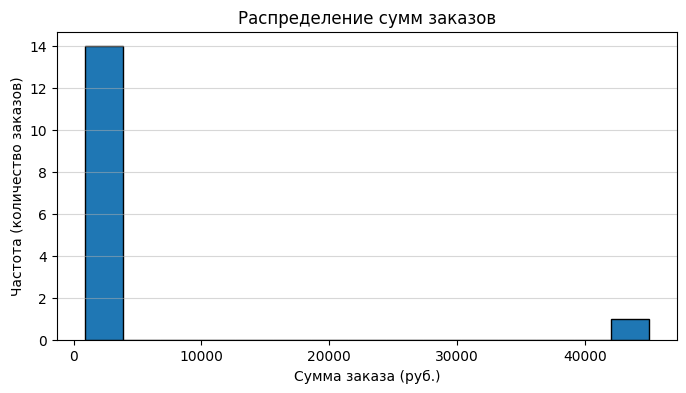

In [6]:
import matplotlib.pyplot as plt

# 11. Построение гистограммы распределения суммы заказов
plt.figure(figsize=(8, 4))
store_df["order_sum"].plot(kind="hist", bins=15, edgecolor="black")

plt.title("Распределение сумм заказов")
plt.xlabel("Сумма заказа (руб.)")
plt.ylabel("Частота (количество заказов)")
plt.grid(axis="y", alpha=0.5)
plt.show()

### Анализ гистограммы распределения суммы заказов (Дополнительное задание)

1. **Характер распределения:**
   Подавляющее большинство наблюдений (14 из 15 заказов, или 93.3%) сосредоточено в левой части диапазона — от 900 до 3 600 рублей.
2. **Влияние аномального выброса:**
   Одиночный заказ на сумму 45 000 рублей растягивает горизонтальную ось $X$ в десятки раз. Из-за этого масштабирование графика искажается: 14 стандартных заказов «спрессовались» в один узкий столбец около нуля, а пространство от 4 000 до 45 000 рублей пустует.
3. **Вывод:**
   Наличие сильного выброса делает базовую гистограмму малоинформативной для анализа структуры типичных покупок. Для корректной визуализации таких данных требуется либо предварительное исключение аномалий (фильтрация выбросов), либо использование логарифмической шкалы по оси $X$.